In [1]:
!pip install yfinance

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 372.0 kB/s eta 0:00:04
   ---------- ----------------------------- 0.5/2.0 MB 372.0 kB/s eta 0:00:04
   --------------- ------------------------ 0.8/2.0 MB 439.5 kB/s eta 0:00:03
   --------------- ------------------------ 0.8/2.0 MB 439.5 kB/s eta 0:00:03
   --------------------- ------------------ 1.0/2.0 MB 509.2 kB/s eta 0:00:02
   --------------------- ------------------ 1.0/2.0 MB 509.2 kB/s eta 0:00:02
   -------------------------- ------------- 1.3/2.0 MB 492.2 kB/s eta 0:00:02
   -------------------------- ----------

In [2]:
import seaborn as sns
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

In [3]:

btc = yf.Ticker('BTC-USD')
prices1 = btc.history(period='5y')
prices1.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

eth = yf.Ticker('ETH-USD')
prices2 = eth.history(period='5y')
prices2.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

usdt = yf.Ticker('USDT-USD')
prices3 = usdt.history(period='5y')
prices3.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

bnb = yf.Ticker('BNB-USD')
prices4 = bnb.history(period='5y')
prices4.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

In [4]:
p1 = prices1.join(prices2, lsuffix = ' (BTC)', rsuffix = ' (ETH)')
p2 = prices3.join(prices4, lsuffix = ' (USDT)', rsuffix = ' (BNB)')
data = p1.join(p2, lsuffix = '_', rsuffix = '_')

In [5]:
data.head()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2021-10-21 00:00:00+00:00,62210.171875,45908121370,4054.322754,28220661820,1.000022,84189482202,471.256927,3081793454
2021-10-22 00:00:00+00:00,60692.265625,38434082775,3970.181885,19432937968,0.999879,73919161798,478.643158,1962748496
2021-10-23 00:00:00+00:00,61393.617188,26882546034,4171.663574,14781537792,1.000823,55395032239,485.906433,1170864603
2021-10-24 00:00:00+00:00,60930.835938,27316183882,4087.903076,14978083638,1.000223,66669467996,476.633118,1246191889
2021-10-25 00:00:00+00:00,63039.824219,31064911614,4217.876953,15995727040,0.999375,66194185821,484.645081,1337787876


In [6]:
data.tail()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2026-10-16 00:00:00+00:00,81500.804688,26591693705,2419.767334,11773801739,0.998603,63342250194,720.894043,1309402321
2026-10-17 00:00:00+00:00,81382.148438,11535072090,2399.799072,5915110956,0.998715,35607186974,717.042175,1072065355
2026-10-18 00:00:00+00:00,82017.601562,18492770661,2408.741455,7944320489,0.998815,44956653893,722.255371,1130217153
2026-10-19 00:00:00+00:00,81853.539062,24424961001,2404.815186,8636807435,0.998820,55785483354,730.955383,1303855781
2026-10-21 00:00:00+00:00,82751.453125,25491812352,2440.379883,11102662656,0.998820,59834257408,743.799988,1306884096


In [7]:
data.shape

(1826, 8)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1826 entries, 2021-10-21 00:00:00+00:00 to 2026-10-21 00:00:00+00:00
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close (BTC)    1826 non-null   float64
 1   Volume (BTC)   1826 non-null   int64  
 2   Close (ETH)    1826 non-null   float64
 3   Volume (ETH)   1826 non-null   int64  
 4   Close (USDT)   1826 non-null   float64
 5   Volume (USDT)  1826 non-null   int64  
 6   Close (BNB)    1826 non-null   float64
 7   Volume (BNB)   1826 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 128.4 KB


In [9]:
data.isna().sum()

Close (BTC)      0
Volume (BTC)     0
Close (ETH)      0
Volume (ETH)     0
Close (USDT)     0
Volume (USDT)    0
Close (BNB)      0
Volume (BNB)     0
dtype: int64

In [10]:
data.describe()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
count,1826.000000,1.826000e+03,1826.000000,1.826000e+03,1826.000000,1.826000e+03,1826.000000,1.826000e+03
mean,58983.588412,3.458472e+10,2503.534252,1.755779e+10,0.999969,6.763876e+10,511.335640,1.624520e+09
std,29893.336714,2.059882e+10,875.890748,1.185210e+10,0.000664,4.225718e+10,219.859763,1.087634e+09
min,15787.284180,5.331173e+09,993.636780,2.081626e+09,0.995872,9.989859e+09,197.042999,2.038465e+08
25%,29410.323730,2.028216e+10,1810.140747,9.419045e+09,0.999659,3.928556e+10,304.741547,9.021106e+08
50%,60938.324219,3.005127e+10,2371.458374,1.493890e+10,1.000060,5.791304e+10,556.639130,1.514281e+09
75%,82567.693359,4.257440e+10,3118.340332,2.173442e+10,1.000283,8.340618e+10,642.938980,2.009285e+09
max,124752.531250,1.817464e+11,4831.348633,9.773662e+10,1.007690,3.443980e+11,1310.214355,1.182039e+10


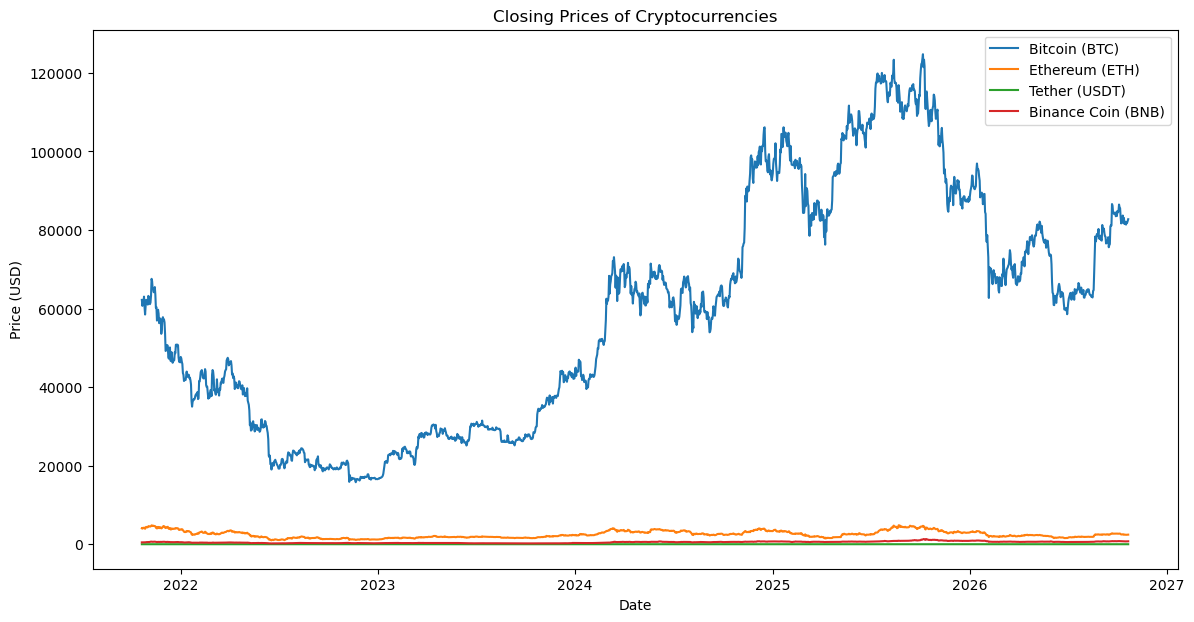

In [11]:
#Visualize the Closing Prices
# create a line plot to visualize the closing prices of all four cryptocurrencies over time:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Close (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Close (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Close (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Close (BNB)'], label='Binance Coin (BNB)')
plt.title('Closing Prices of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

<Axes: xlabel='Date'>

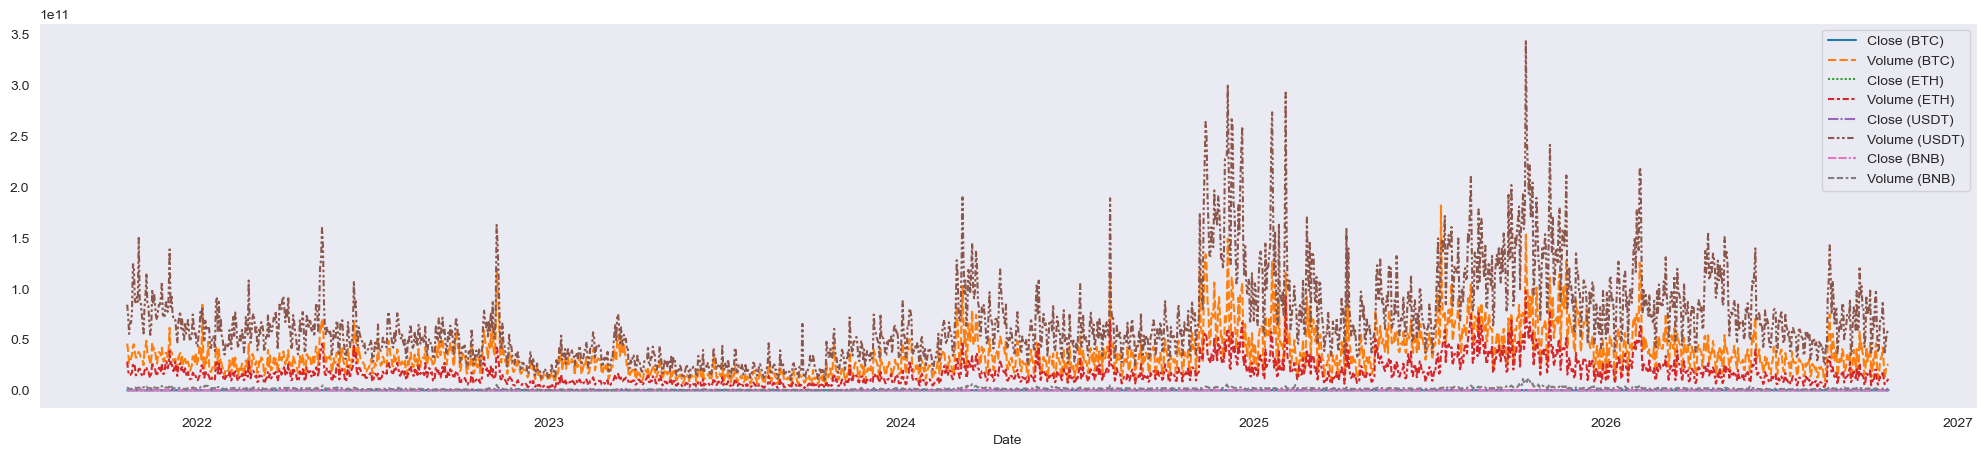

In [12]:
plt.figure(figsize = (25, 5))
sns.set_style('dark')
sns.lineplot(data=data)

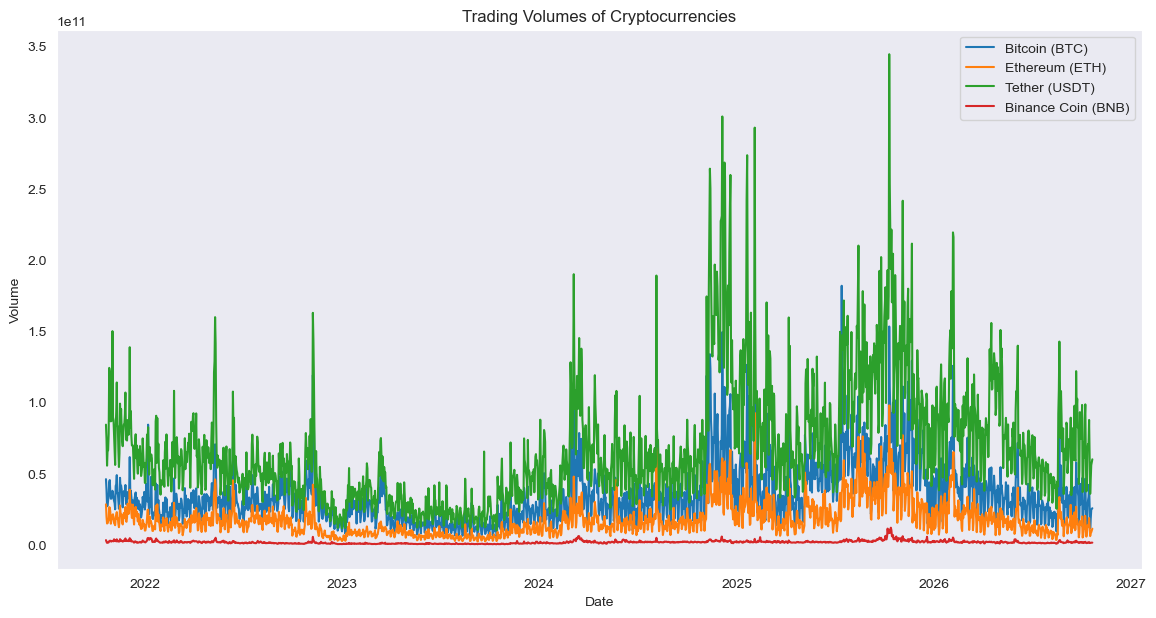

In [13]:
# Visualize the Trading Volumes
#Let's visualize the trading volumes of all four cryptocurrencies:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Volume (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Volume (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Volume (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Volume (BNB)'], label='Binance Coin (BNB)')
plt.title('Trading Volumes of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.show()


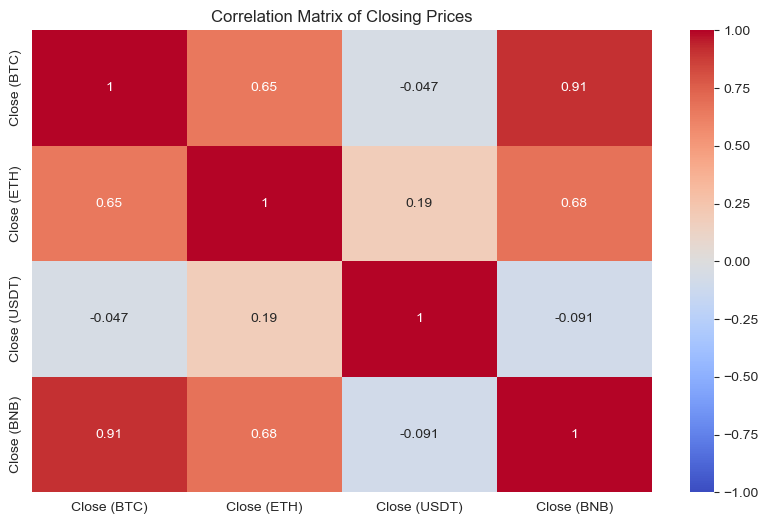

In [14]:
 #Correlation Analysis
#We'll analyze the correlation between the closing prices of the cryptocurrencies:
# Calculate the correlation matrix
corr_matrix = data[['Close (BTC)', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)']].corr()

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Closing Prices')
plt.show()


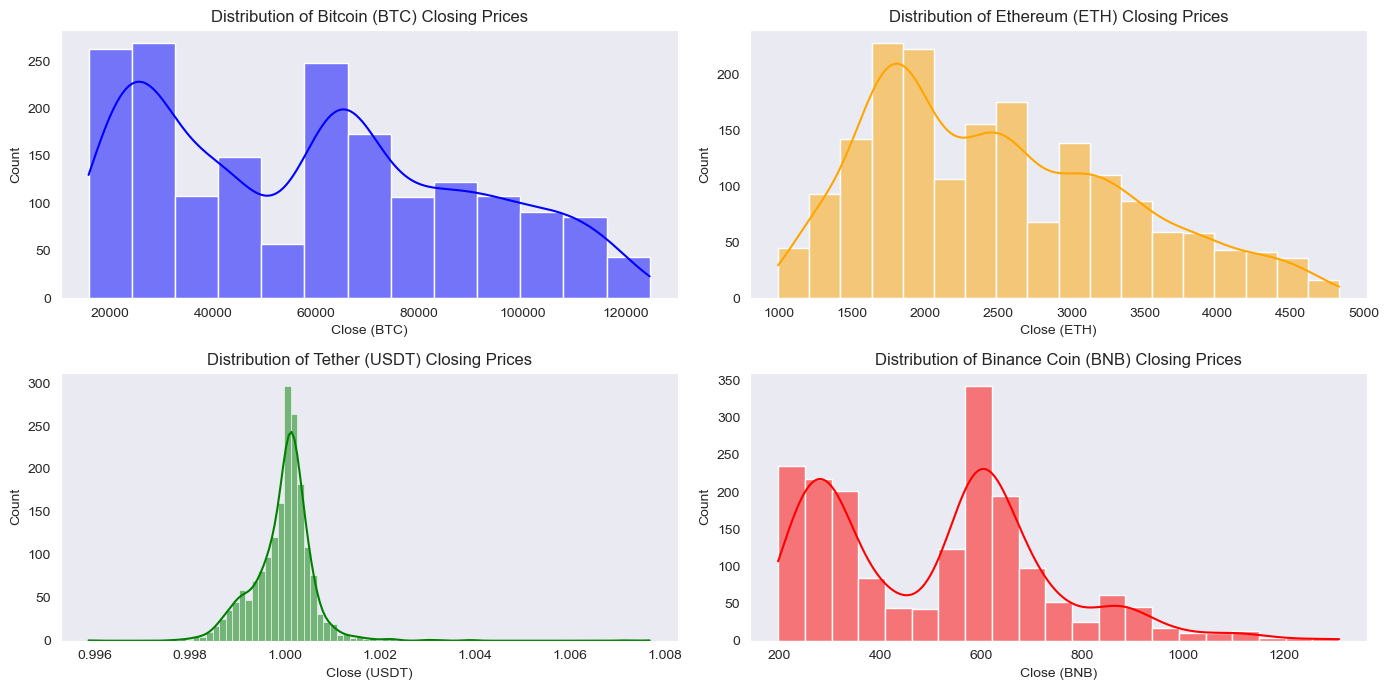

In [15]:
# Distribution of Closing Prices
#Let's plot the distribution of closing prices for each cryptocurrency:
plt.figure(figsize=(14, 7))

plt.subplot(2, 2, 1)
sns.histplot(data['Close (BTC)'], kde=True, color='blue')
plt.title('Distribution of Bitcoin (BTC) Closing Prices')

plt.subplot(2, 2, 2)
sns.histplot(data['Close (ETH)'], kde=True, color='orange')
plt.title('Distribution of Ethereum (ETH) Closing Prices')

plt.subplot(2, 2, 3)
sns.histplot(data['Close (USDT)'], kde=True, color='green')
plt.title('Distribution of Tether (USDT) Closing Prices')

plt.subplot(2, 2, 4)
sns.histplot(data['Close (BNB)'], kde=True, color='red')
plt.title('Distribution of Binance Coin (BNB) Closing Prices')

plt.tight_layout()
plt.show()


array([[<Axes: title={'center': 'Close (BTC)'}>,
        <Axes: title={'center': 'Volume (BTC)'}>,
        <Axes: title={'center': 'Close (ETH)'}>,
        <Axes: title={'center': 'Volume (ETH)'}>],
       [<Axes: title={'center': 'Close (USDT)'}>,
        <Axes: title={'center': 'Volume (USDT)'}>,
        <Axes: title={'center': 'Close (BNB)'}>,
        <Axes: title={'center': 'Volume (BNB)'}>]], dtype=object)

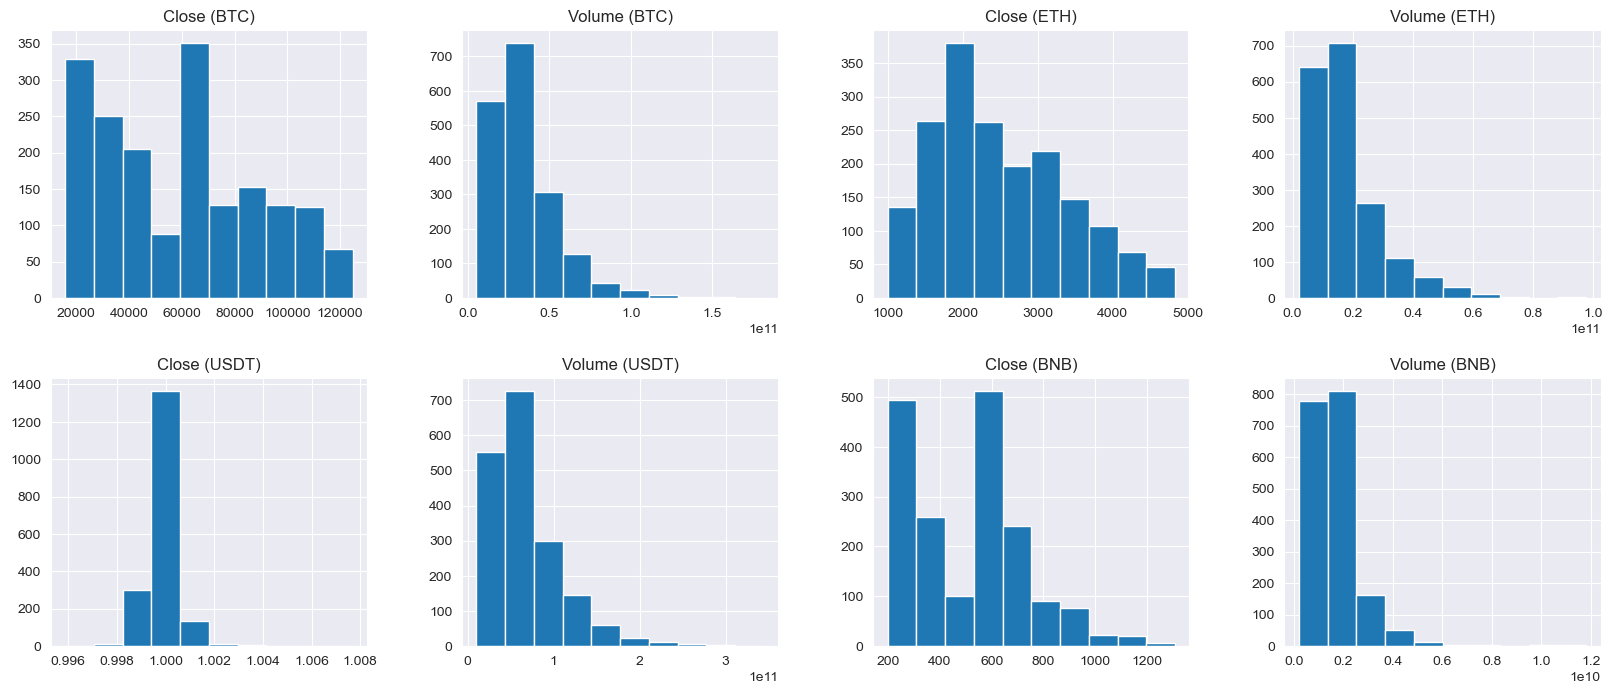

In [16]:
data.hist(figsize=(20, 8), layout=(2, 4))

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>, <Axes: ylabel='Density'>]], dtype=object)

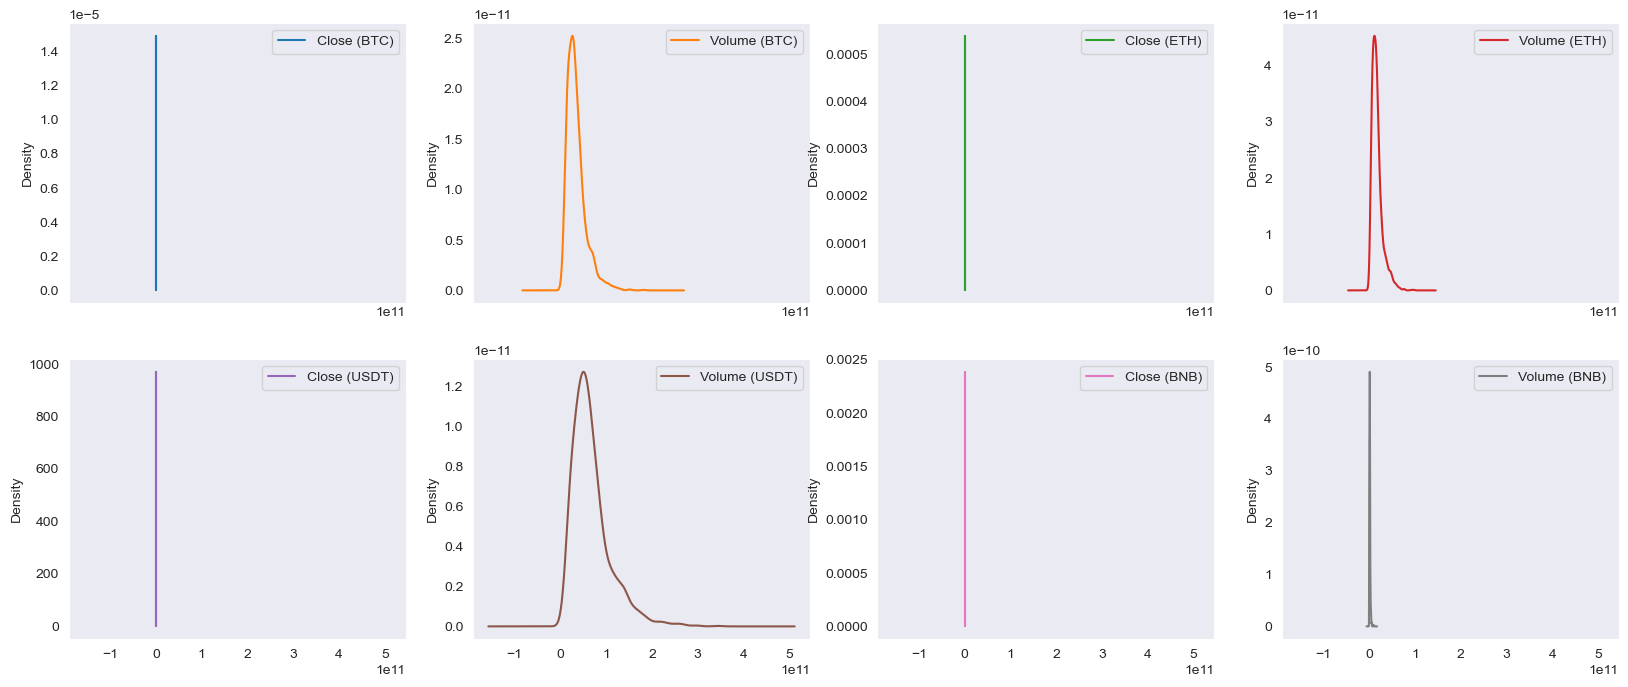

In [17]:
data.plot(kind = "kde", subplots = True, layout = (2, 4), figsize = (20, 8))

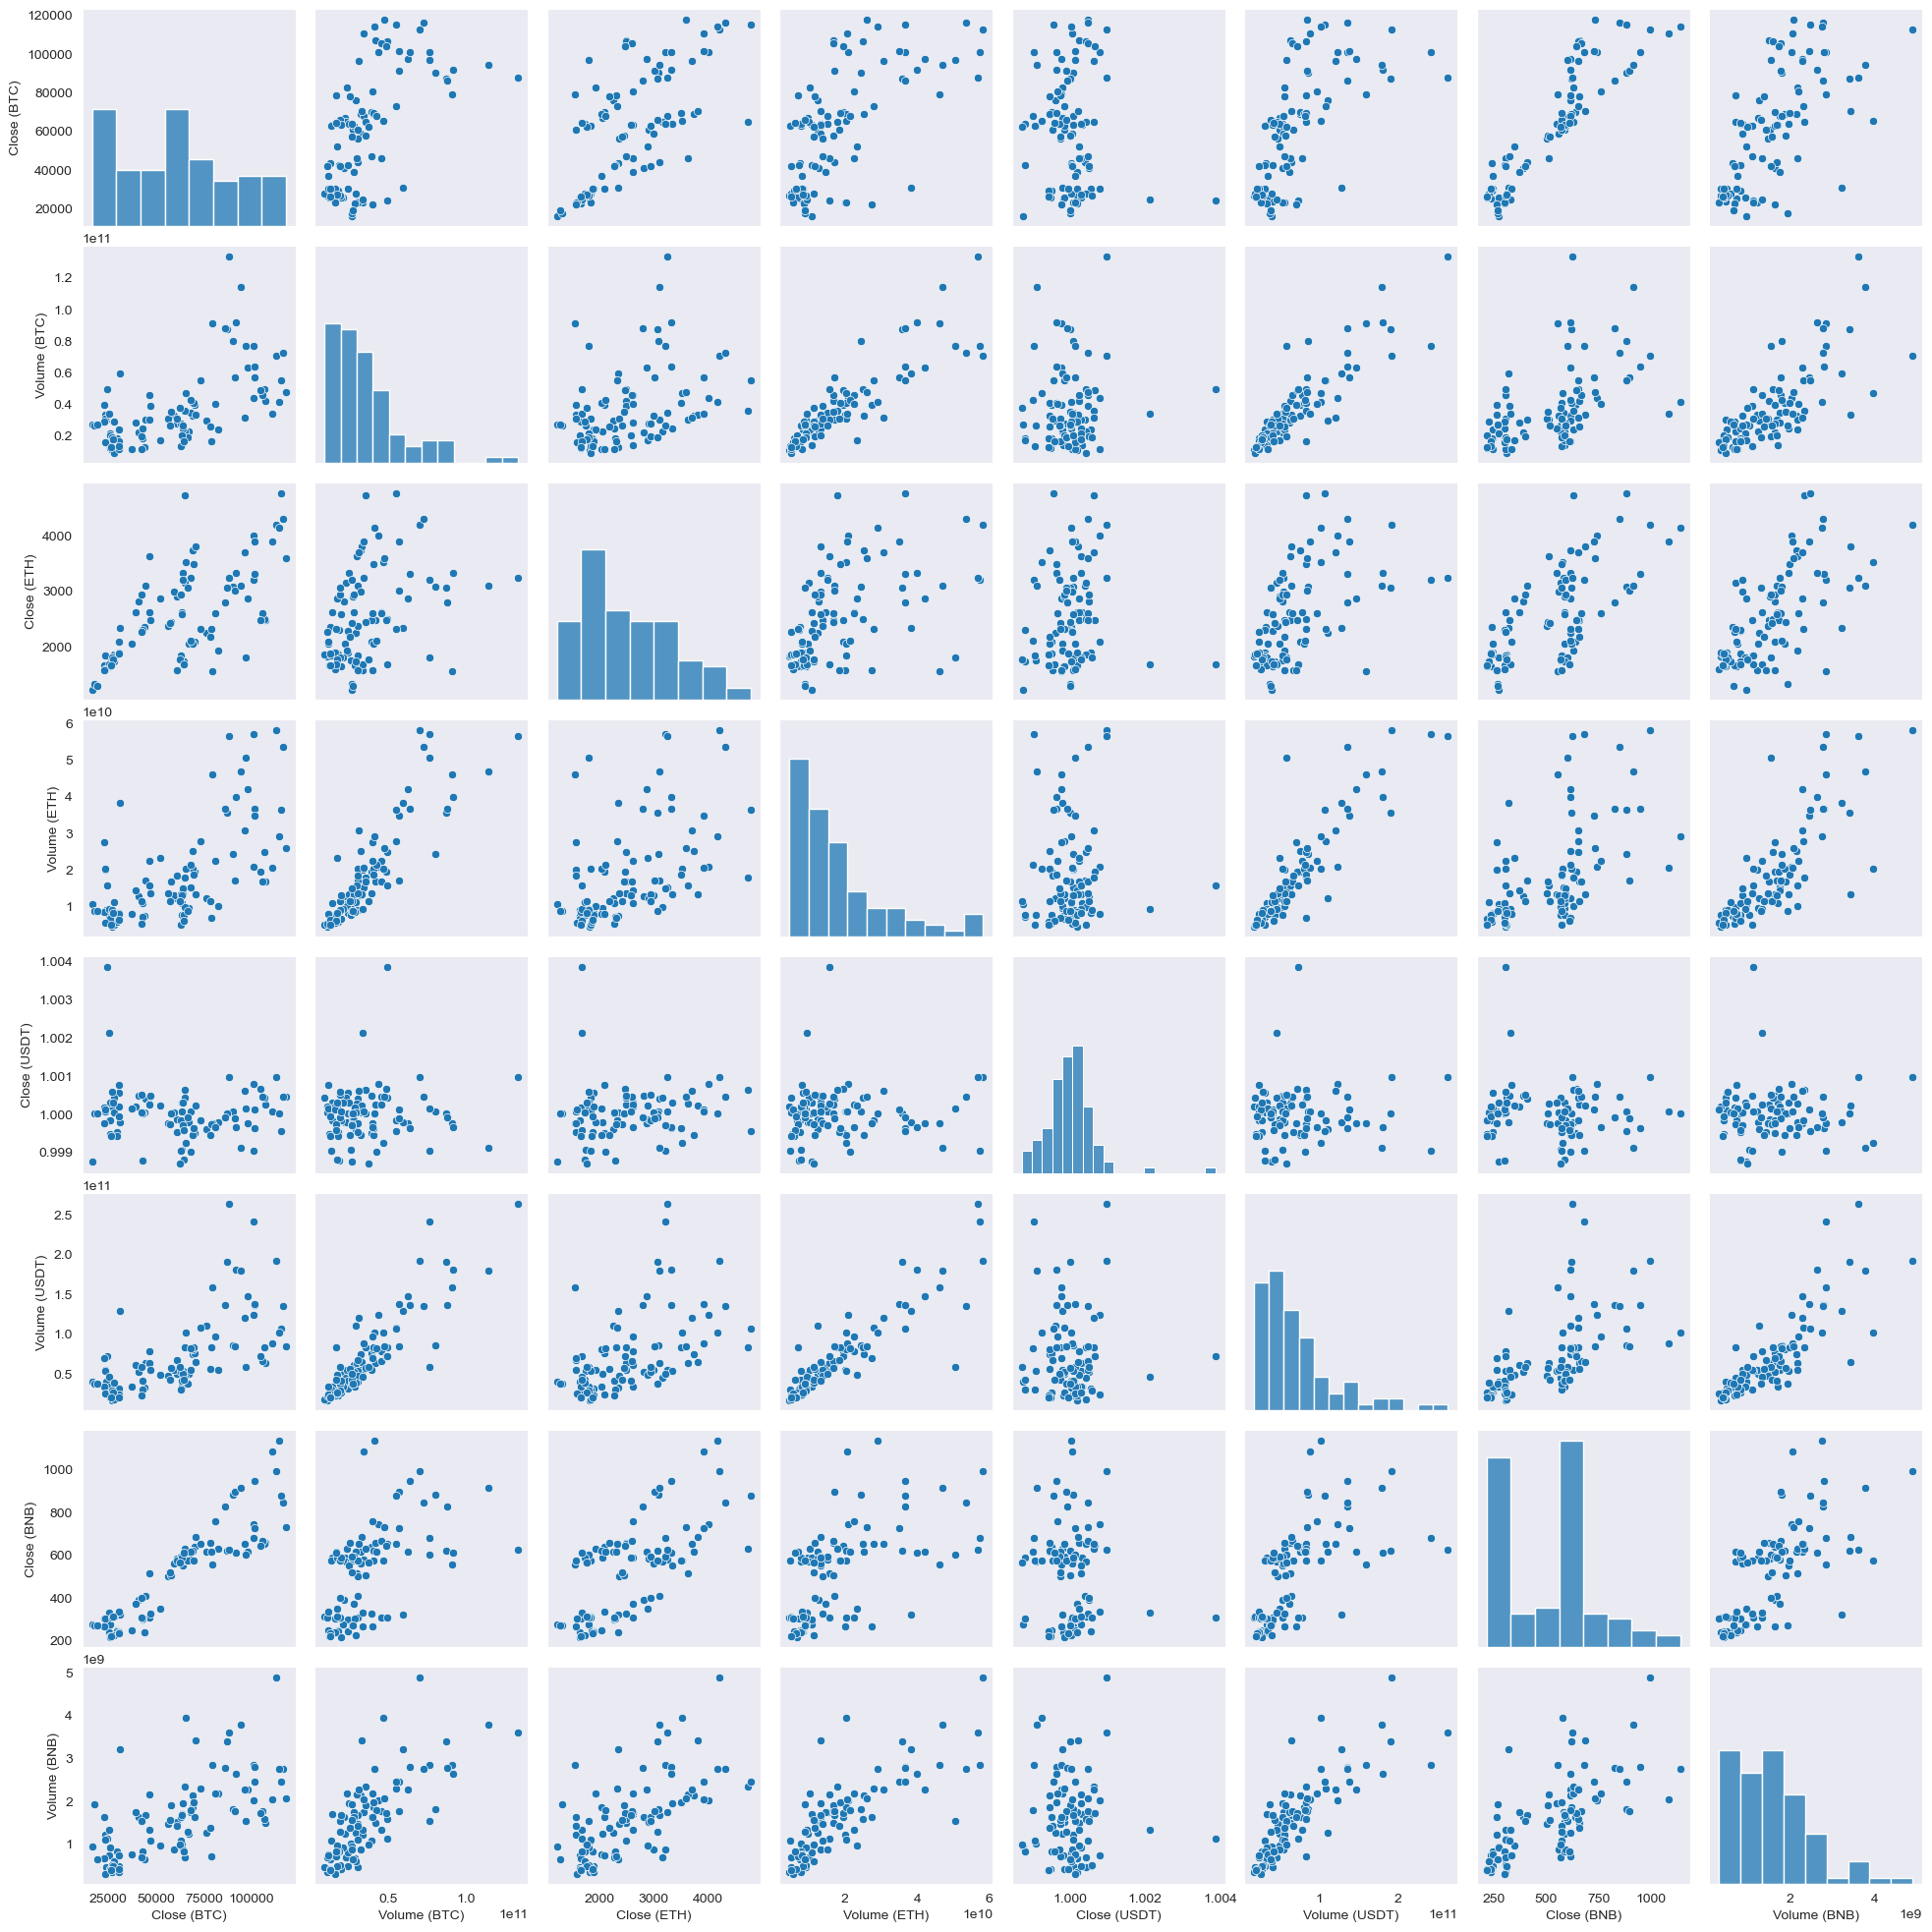

In [18]:
sns.pairplot(data.sample(n=100));

# Data Preprocessing 

In [19]:
X = data.drop(columns = ['Close (BTC)'], axis = 1)
Y = data.loc[:, 'Close (BTC)']

In [21]:
X.head()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2021-10-21 00:00:00+00:00,45908121370,4054.322754,28220661820,1.000022,84189482202,471.256927,3081793454
2021-10-22 00:00:00+00:00,38434082775,3970.181885,19432937968,0.999879,73919161798,478.643158,1962748496
2021-10-23 00:00:00+00:00,26882546034,4171.663574,14781537792,1.000823,55395032239,485.906433,1170864603
2021-10-24 00:00:00+00:00,27316183882,4087.903076,14978083638,1.000223,66669467996,476.633118,1246191889
2021-10-25 00:00:00+00:00,31064911614,4217.876953,15995727040,0.999375,66194185821,484.645081,1337787876


In [22]:
X.tail()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2026-10-16 00:00:00+00:00,26591693705,2419.767334,11773801739,0.998603,63342250194,720.894043,1309402321
2026-10-17 00:00:00+00:00,11535072090,2399.799072,5915110956,0.998715,35607186974,717.042175,1072065355
2026-10-18 00:00:00+00:00,18492770661,2408.741455,7944320489,0.998815,44956653893,722.255371,1130217153
2026-10-19 00:00:00+00:00,24424961001,2404.815186,8636807435,0.998820,55785483354,730.955383,1303855781
2026-10-21 00:00:00+00:00,25491812352,2440.379883,11102662656,0.998820,59834257408,743.799988,1306884096


In [23]:
Y.head()

Date
2021-10-21 00:00:00+00:00    62210.171875
2021-10-22 00:00:00+00:00    60692.265625
2021-10-23 00:00:00+00:00    61393.617188
2021-10-24 00:00:00+00:00    60930.835938
2021-10-25 00:00:00+00:00    63039.824219
Name: Close (BTC), dtype: float64

In [24]:
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [25]:
# Print the shapes of the resulting datasets
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {Y_train.shape}')
print(f'y_test shape: {Y_test.shape}')

X_train shape: (1460, 7)
X_test shape: (366, 7)
y_train shape: (1460,)
y_test shape: (366,)


In [26]:
#SelectKBest
#SelectKBest is a feature selection method provided by scikit-learn (sklearn) that selects the top k features based on a specified scoring function.
#This function evaluates each feature independently and selects those that have the strongest relationship with the target variable.

#Parameters
#k: Specifies the number of top features to select. In your case, k=4 indicates that you want to select the top 4 features

from sklearn.feature_selection import SelectKBest

fs = SelectKBest(k=4)
X_train = fs.fit_transform(X_train, Y_train)
X_test = fs.transform(X_test)

C:\Users\aisha\AppData\Local\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:107: RuntimeWarning: invalid value encountered in divide
  msw = sswn / float(dfwn)


In [27]:
mask = fs.get_support()
selected_features = X.columns[mask]
print("Selected Features:", selected_features) 

Selected Features: Index(['Close (USDT)', 'Volume (USDT)', 'Close (BNB)', 'Volume (BNB)'], dtype='object')


In [28]:
X_train

array([[9.99603987e-01, 1.11108953e+11, 6.15066711e+02, 1.27175983e+09],
       [1.00026596e+00, 1.21507256e+11, 9.02983337e+02, 2.25055181e+09],
       [9.99406993e-01, 1.67234231e+11, 9.28046631e+02, 3.03445228e+09],
       ...,
       [9.99804974e-01, 1.19458344e+11, 6.15331055e+02, 1.37344655e+09],
       [1.00027096e+00, 2.97878635e+10, 3.26212891e+02, 8.22037855e+08],
       [9.99584019e-01, 1.83237280e+10, 2.14478134e+02, 2.98056096e+08]],
      shape=(1460, 4))

In [29]:
#MinMaxScaler is a preprocessing method in scikit-learn that transforms features by scaling them to a specified range.
# It's often used when your data needs to be normalized within a specific range to ensure all features contribute equally to the analysis.
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [30]:
# implementation of 10 different regression algorithms using scikit-learn. Each algorithm is trained and evaluated on a sample dataset:

#Import Libraries and Generate Sample Data

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

----- Linear Regression -----
Mean Squared Error (MSE): 128268131.34125403
R-squared: 0.8519739802180144

----- Ridge Regression -----
Mean Squared Error (MSE): 130142733.09935911
R-squared: 0.8498106226168161

----- Lasso Regression -----
Mean Squared Error (MSE): 128255011.95857333
R-squared: 0.851989120455733

----- ElasticNet Regression -----
Mean Squared Error (MSE): 744485251.6497678
R-squared: 0.14083734255929625

----- Support Vector Regression (SVR) -----
Mean Squared Error (MSE): 859666522.0957856
R-squared: 0.007914029190086436

----- Decision Tree Regression -----
Mean Squared Error (MSE): 106610071.0968999
R-squared: 0.876968157810271

----- Random Forest Regression -----
Mean Squared Error (MSE): 49071521.06078828
R-squared: 0.9433697063228351

----- Gradient Boosting Regression -----
Mean Squared Error (MSE): 56073108.579764344
R-squared: 0.9352896234390213

----- K-Nearest Neighbors Regression -----
Mean Squared Error (MSE): 55394626.347025394
R-squared: 0.9360726162475

C:\Users\aisha\AppData\Local\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


----- Neural Network Regression (MLP) -----
Mean Squared Error (MSE): 531027498.62575084
R-squared: 0.3871752383511007

                             Model           MSE  R-squared
0                Linear Regression  1.282681e+08   0.851974
1                 Ridge Regression  1.301427e+08   0.849811
2                 Lasso Regression  1.282550e+08   0.851989
3            ElasticNet Regression  7.444853e+08   0.140837
4  Support Vector Regression (SVR)  8.596665e+08   0.007914
5         Decision Tree Regression  1.066101e+08   0.876968
6         Random Forest Regression  4.907152e+07   0.943370
7     Gradient Boosting Regression  5.607311e+07   0.935290
8   K-Nearest Neighbors Regression  5.539463e+07   0.936073
9  Neural Network Regression (MLP)  5.310275e+08   0.387175


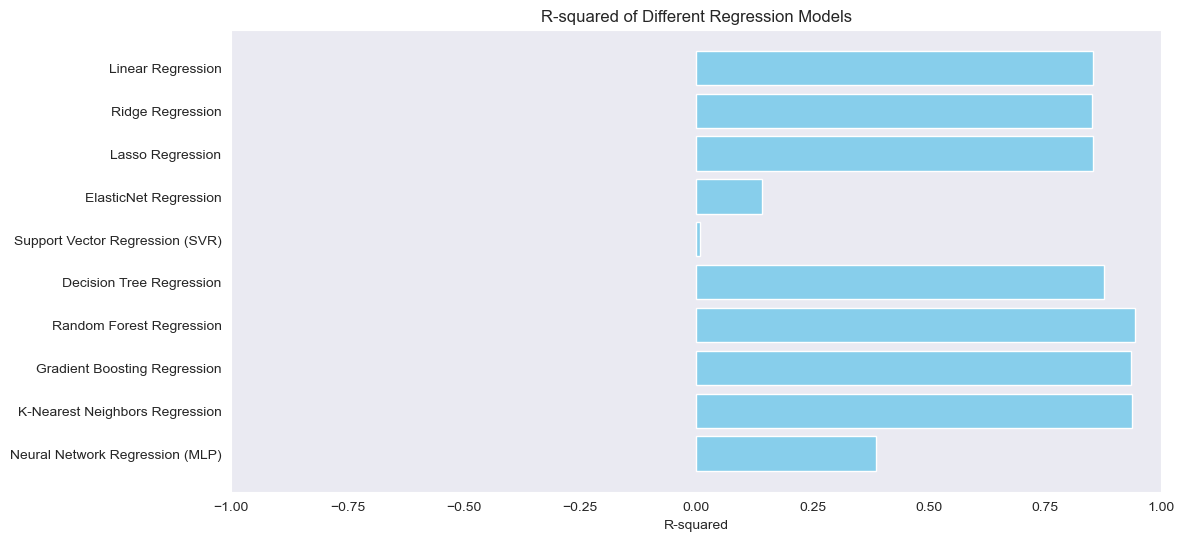

In [31]:
#Define Models and Perform Training and Evaluation
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'ElasticNet Regression': ElasticNet(alpha=1.0, l1_ratio=0.5),
    'Support Vector Regression (SVR)': SVR(kernel='rbf'),
    'Decision Tree Regression': DecisionTreeRegressor(),
    'Random Forest Regression': RandomForestRegressor(n_estimators=100),
    'Gradient Boosting Regression': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1),
    'K-Nearest Neighbors Regression': KNeighborsRegressor(n_neighbors=5),
    'Neural Network Regression (MLP)': MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam')
}

# Train and evaluate each model
results = {'Model': [], 'MSE': [], 'R-squared': []}

for name, model in models.items():
    # Train the model
    model.fit(X_train, Y_train)

    # Predict on test set
    Y_pred = model.predict(X_test)

    # Evaluate model
    mse = mean_squared_error(Y_test, Y_pred)
    r2 = r2_score(Y_test, Y_pred)

    # Store results
    results['Model'].append(name)
    results['MSE'].append(mse)
    results['R-squared'].append(r2)

    # Print results
    print(f"----- {name} -----")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"R-squared: {r2}")
    print()

# Convert results to DataFrame for visualization
results_df = pd.DataFrame(results)
print(results_df)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.barh(results_df['Model'], results_df['R-squared'], color='skyblue')
plt.xlabel('R-squared')
plt.title('R-squared of Different Regression Models')
plt.xlim(-1, 1)
plt.gca().invert_yaxis()
plt.show()

In [32]:
import pickle
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

# Generate sample data
X, Y = make_regression(n_samples=1000, n_features=10, noise=0.1, random_state=0)


# Scale the features (optional but recommended for some algorithms)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, random_state=0)

# Train the model
model_rf.fit(X_train, Y_train)

# Save the model to a file
filename = 'random_forest_model.pkl'
pickle.dump(model_rf, open(filename, 'wb'))

# Save scaler to a file
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Load the model from the file
loaded_model = pickle.load(open(filename, 'rb'))

# Predict using the loaded model
Y_pred = loaded_model.predict(X_test)

# Evaluate the loaded model
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f"Loaded Random Forest Regression - Mean Squared Error (MSE): {mse}")
print(f"Loaded Random Forest Regression - R-squared: {r2}")


Loaded Random Forest Regression - Mean Squared Error (MSE): 49417349.43881499
Loaded Random Forest Regression - R-squared: 0.9429706079825719
